# I-S40 - ISLES2022 SegResNetDS + Dice-Focal

- Input: DWI + ADC
- Single change: Sampling only: foreground patches centered on small connected components
- All other settings match I-N20
- 300 epochs; full-volume validation every 10 epochs from epoch 150
- Evaluate Top-3 +/-5 epochs, then save best-epoch probability maps
- Threshold 0.10-0.90: Dice, lesion recall/precision/F2, FP/scan, <0.1mL recall


In [1]:
from pathlib import Path
import json, os, subprocess, time
import pandas as pd

ROOT = Path("/home/stu03/workspace/model")
CONFIG = ROOT / "configs/experiments/ischemia/I-S40.yaml"
DATA_ROOT = Path("/home/stu03/workspace/datasets/ischemic/SegResNet")
RESULTS_ROOT = ROOT / "runs/I-segresnet"
PYTHON = ROOT / ".venv/bin/python"
LAUNCHER = ROOT / "scripts/ischemia/training/run_i_s40.py"
MODEL_NAME = "I-S40"
FOLD = RESULTS_ROOT / MODEL_NAME
PROGRESS = FOLD / "progress.json"
HISTORY = FOLD / "full_validation_history.json"
PID_FILE = FOLD / "train.pid"
LOG_FILE = FOLD / "train.log"

for name, path in {"config": CONFIG, "data": DATA_ROOT, "python": PYTHON, "launcher": LAUNCHER}.items():
    print(f"{name:10s} {path.exists()}  {path}")


config     True  /home/stu03/workspace/model/configs/experiments/ischemia/I-S40.yaml
data       True  /home/stu03/workspace/datasets/ischemic/SegResNet
python     True  /home/stu03/workspace/model/.venv/bin/python
launcher   True  /home/stu03/workspace/model/scripts/ischemia/training/run_i_s40.py


## 1. Dry-run 및 동일 split 확인


In [2]:
base = [str(PYTHON), str(LAUNCHER), "--config", str(CONFIG), "--data-root", str(DATA_ROOT)]
subprocess.run(base + ["--dry-run"], cwd=ROOT, check=True)

split_path = Path("/home/stu03/workspace/datasets/ischemic/nnunet/nnUNet_preprocessed/Dataset502_ISLES2022/splits_final.json")
split = json.loads(split_path.read_text(encoding="utf-8"))[0]
seg_train = {p.name.removesuffix("_dwi.nii.gz") for p in (DATA_ROOT / "train/images").glob("*_dwi.nii.gz")}
seg_val = {p.name.removesuffix("_dwi.nii.gz") for p in (DATA_ROOT / "val/images").glob("*_dwi.nii.gz")}
assert seg_train == set(split["train"])
assert seg_val == set(split["val"])
assert len(list((DATA_ROOT / "test/images").glob("*_dwi.nii.gz"))) == 37
print("nnU-Net fold 0과 동일한 175/38/37 split: PASS")


{
  "experiment": "I-S40",
  "mode": "new",
  "data_root": "/home/stu03/workspace/datasets/ischemic/SegResNet",
  "results": "/home/stu03/workspace/model/runs/I-segresnet/I-S40",
  "command": [
    "/home/stu03/workspace/model/.venv/bin/python",
    "-m",
    "brainon_ai.models.ischemia.segresnet_hy.train",
    "--config",
    "/home/stu03/workspace/model/configs/experiments/ischemia/I-S40.yaml",
    "--data-root",
    "/home/stu03/workspace/datasets/ischemic/SegResNet",
    "--backup-root",
    "/home/stu03/workspace/model/runs/I-segresnet/I-S40"
  ]
}
nnU-Net fold 0과 동일한 175/38/37 split: PASS


## 2. GPU 확인 및 학습 시작/재개

이미 PID가 실행 중이면 중복으로 시작하지 않습니다.


In [3]:
subprocess.run(["nvidia-smi"], check=False)
PID_FILE.parent.mkdir(parents=True, exist_ok=True)
LOG_FILE.parent.mkdir(parents=True, exist_ok=True)

def pid_running():
    if not PID_FILE.is_file():
        return False
    try:
        pid = int(PID_FILE.read_text().strip())
        return subprocess.run(["kill", "-0", str(pid)], capture_output=True).returncode == 0
    except (ValueError, OSError):
        return False

if pid_running():
    print("이미 실행 중 PID:", PID_FILE.read_text().strip())
else:
    log = LOG_FILE.open("a", encoding="utf-8")
    process = subprocess.Popen(base, cwd=ROOT, stdout=log, stderr=subprocess.STDOUT, start_new_session=True)
    PID_FILE.write_text(str(process.pid), encoding="utf-8")
    print("I-S40 시작 PID:", process.pid)
    print("로그:", LOG_FILE)


Tue Sep 15 19:07:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.84                 Driver Version: 595.84         CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5090        Off |   00000000:01:00.0 Off |                  N/A |
|  0%   40C    P8             13W /  575W |       4MiB /  32607MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 3. 실시간 진행률

셀 중지는 모니터만 멈추며 학습 프로세스는 계속 실행됩니다.


In [4]:
from IPython.display import clear_output, display

def read_json(path, default=None):
    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except (FileNotFoundError, json.JSONDecodeError):
        return {} if default is None else default

def fmt(seconds):
    if seconds is None:
        return "-"
    seconds = int(seconds)
    return f"{seconds//3600:02d}:{seconds%3600//60:02d}:{seconds%60:02d}"

while True:
    clear_output(wait=True)
    p = read_json(PROGRESS)
    history = read_json(HISTORY, [])
    running = pid_running()
    ranked = sorted(history, key=lambda x: x.get("macro_dice_positive", -1), reverse=True)[:3]
    row = {
        "실험": "I-S40", "상태": p.get("status", "starting" if running else "not_started"),
        "Epoch": f'{p.get("current_epoch", 0)}/{p.get("total_epochs", 300)}',
        "진행률(%)": p.get("progress_percent", 0), "ETA": fmt(p.get("eta_seconds")),
        "Online Dice": p.get("pseudo_dice"), "Online Recall": p.get("pseudo_recall"),
        "Composite": p.get("composite"), "Full Macro Dice": p.get("full_macro_dice"),
        "Best Full Dice": p.get("best_full_macro_dice"),
        "Top-3": [(x.get("epoch"), round(x.get("macro_dice_positive", 0), 4)) for x in ranked],
        "보존 CKPT": p.get("retained_epoch_checkpoints"), "PID": PID_FILE.read_text().strip() if running else "-",
    }
    display(pd.DataFrame([row]))
    if LOG_FILE.is_file():
        print("\n로그 마지막 15줄:\n", "".join(LOG_FILE.read_text(errors="replace").splitlines(True)[-15:]))
    status = p.get("status")
    if status in {"completed", "early_stopped", "failed"}:
        print("학습 프로세스 종료:", status)
        break
    if not running and p:
        print("PID가 종료되었습니다. 로그의 traceback을 확인하세요.")
        break
    time.sleep(10)


,실험,상태,Epoch,진행률(%),ETA,Online Dice,Online Recall,Composite,Full Macro Dice,Best Full Dice,Top-3,보존 CKPT,PID
0,I-S40,completed,300/300,100.0,00:00:00,None,None,None,0.727816,0.761408,"[(270, 0.7614), (250, 0.7597), (220, 0.7565)]",33,2156369



로그 마지막 15줄:
       "epoch": 274,
      "macro_dice_positive": 0.7537280783973959,
      "lesion_detection_rate": 0.6297872340425532,
      "checkpoint": "/home/stu03/workspace/model/runs/I-segresnet/I-S40/checkpoints/epoch_checkpoints/checkpoint_epoch_0274.pth",
      "evaluation": "/home/stu03/workspace/model/runs/I-segresnet/I-S40/selection_evaluation/epoch_0274"
    }
  ],
  "selected": {
    "epoch": 274,
    "macro_dice_positive": 0.7537280783973959,
    "lesion_detection_rate": 0.6297872340425532,
    "checkpoint": "/home/stu03/workspace/model/runs/I-segresnet/I-S40/checkpoints/epoch_checkpoints/checkpoint_epoch_0274.pth",
    "evaluation": "/home/stu03/workspace/model/runs/I-segresnet/I-S40/selection_evaluation/epoch_0274"
  }
}

학습 프로세스 종료: completed


## 4. 최종 선택 및 평가 결과 확인


In [5]:
best_checkpoint = FOLD / "checkpoints/checkpoint_best.pth"
metadata_path = FOLD / "final_metrics/val_evaluation_metadata.json"
if not best_checkpoint.is_file():
    print("아직 checkpoint_best.pth가 없습니다.")
else:
    checkpoint = __import__("torch").load(best_checkpoint, map_location="cpu", weights_only=False)
    selected = {"epoch": int(checkpoint["epoch"]) + 1, "macro_dice_positive": float(checkpoint["best_dice"])}
    if metadata_path.is_file():
        metadata = read_json(metadata_path)
        selected["macro_dice_positive"] = metadata["macro_metrics_gt_positive"]["dice"]
    selection = {"selected": selected}
    display(pd.DataFrame([{"epoch": selected["epoch"], "macro_dice": selected["macro_dice_positive"], "selection_rule": "best validation Dice"}]))
    print("checkpoint:", best_checkpoint)
    print("확률맵:", FOLD / "final_metrics/val_probabilities")


,epoch,macro_dice,selection_rule
0,270,0.753728,best validation Dice


checkpoint: /home/stu03/workspace/model/runs/I-segresnet/I-S40/checkpoints/checkpoint_best.pth
확률맵: /home/stu03/workspace/model/runs/I-segresnet/I-S40/final_metrics/val_probabilities


## 5. Lesion Dice and detection rate by size

I-S40은 validation case의 총 병변 부피 기준으로 크기별 성능을 표시합니다.


,size_group,n_cases,mean_lesion_volume_ml,median_lesion_volume_ml,macro_dice,macro_iou,macro_precision,macro_recall_sensitivity,macro_hd95_mm,macro_assd_mm
0,Small (<5 mL),16,1.518000,1.004,0.711702,0.577434,0.810969,0.695799,21.111782,3.828799
1,Medium (5-20 mL),15,11.160000,10.616,0.776971,0.652024,0.845270,0.766970,5.271263,1.217357
2,Large (>=20 mL),6,68.069333,72.140,0.807691,0.696964,0.927854,0.745737,5.706565,1.495104


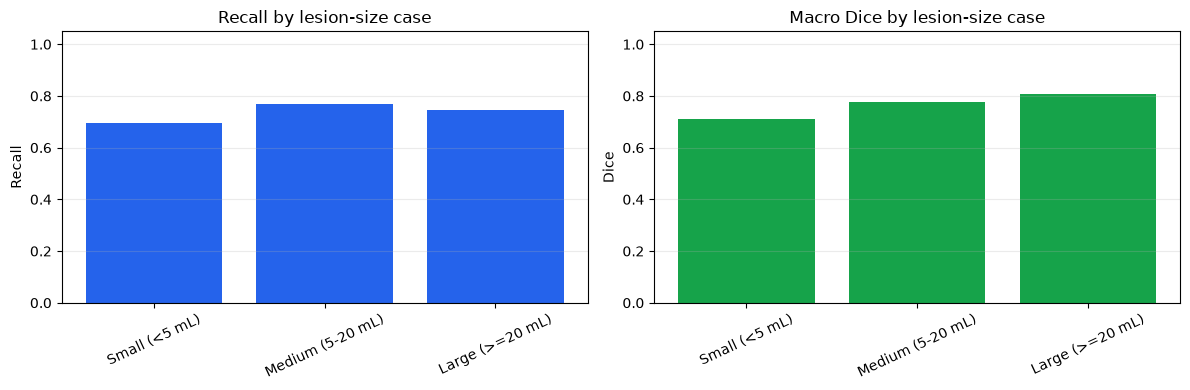

In [6]:
size_path = FOLD / "final_metrics/val_size_group_summary.csv"
if not size_path.is_file():
    print("크기별 평가 결과가 아직 없습니다.")
else:
    size_df = pd.read_csv(size_path)
    display(size_df)

    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].bar(size_df["size_group"].astype(str), size_df["macro_recall_sensitivity"], color="#2563eb")
    axes[0].set(title="Recall by lesion-size case", ylabel="Recall", ylim=(0, 1.05))
    axes[1].bar(size_df["size_group"].astype(str), size_df["macro_dice"], color="#16a34a")
    axes[1].set(title="Macro Dice by lesion-size case", ylabel="Dice", ylim=(0, 1.05))
    for ax in axes:
        ax.tick_params(axis="x", rotation=25)
        ax.grid(axis="y", alpha=0.25)
    plt.tight_layout(); plt.show()


## 6. 최종 핵심 지표

Voxel overlap, 병변 검출, 경계 거리 및 병변 부피 오차를 함께 확인합니다.


In [7]:
metadata_path = FOLD / "final_metrics/val_evaluation_metadata.json"
per_case_path = FOLD / "final_metrics/val_positive_case_metrics.csv"
if not metadata_path.is_file() or not per_case_path.is_file():
    print("final_metrics 결과가 아직 없습니다.")
else:
    metadata = read_json(metadata_path)
    case_df = pd.read_csv(per_case_path)
    overview = dict(metadata["macro_metrics_gt_positive"])
    total_gt = case_df["gt_lesion_count"].sum()
    detected = case_df["detected_gt_lesions"].sum()
    total_pred = case_df["pred_lesion_count"].sum()
    false_positive = case_df["false_positive_lesions"].sum()
    overview.update({"Lesion Recall": detected / total_gt if total_gt else None, "Lesion Precision": (total_pred - false_positive) / total_pred if total_pred else None, "FP/scan": false_positive / metadata["val_cases"], "Complete miss cases": int((case_df["detected_gt_lesions"] == 0).sum())})
    display(pd.DataFrame([overview]).T.rename(columns={0: "value"}))


,value
dice,0.753728
iou,0.627056
precision,0.843829
recall_sensitivity,0.732750
hd95_mm,12.191807
assd_mm,2.391669
Lesion Recall,0.629787
Lesion Precision,0.756881
FP/scan,1.394737
Complete miss cases,0.000000


## 7. Probability threshold evaluation

Evaluate the false-negative/false-positive trade-off. The recommended point maximizes lesion F2 under the configured FP/scan limit.


,operating_point,threshold,macro_dice_positive,lesion_recall,lesion_precision,lesion_f2,fp_per_scan
0,default 0.5,0.5,0.753728,0.629787,0.753425,0.651158,1.421053
1,best Dice,0.4,0.756348,0.629787,0.708696,0.644131,1.763158
2,recommended F2,0.5,0.753728,0.629787,0.753425,0.651158,1.421053


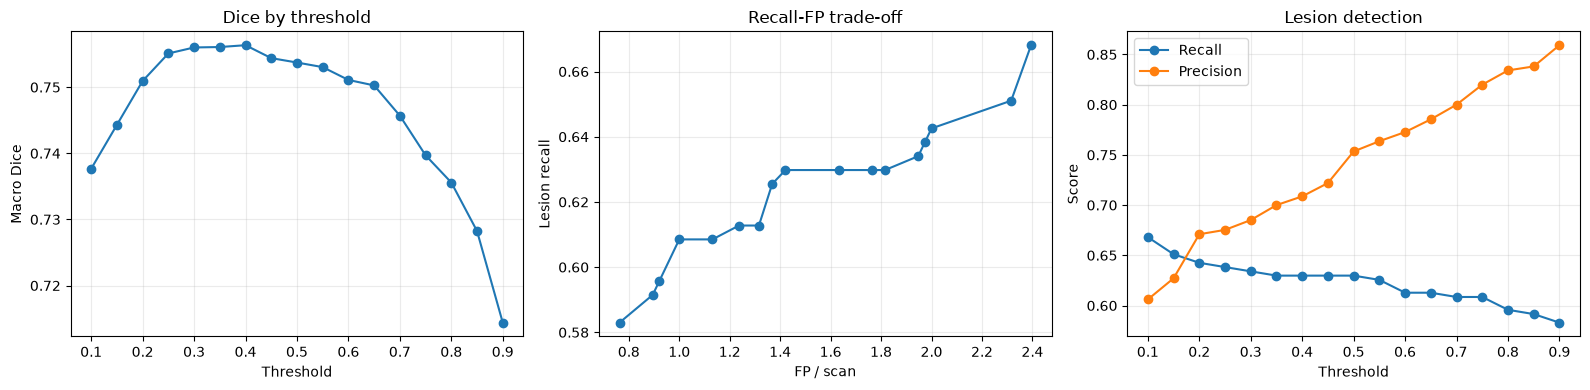

In [8]:
threshold_csv = FOLD / "final_metrics/threshold_sweep.csv"
threshold_json = FOLD / "final_metrics/threshold_summary.json"
if not threshold_csv.is_file():
    print("Threshold results are not available yet. Wait for post-training evaluation.")
else:
    threshold_df = pd.read_csv(threshold_csv)
    threshold_summary = read_json(threshold_json)
    default = threshold_df.iloc[(threshold_df["threshold"] - 0.5).abs().argsort()[:1]].iloc[0].to_dict()
    best_dice = threshold_df.sort_values("macro_dice_positive", ascending=False).iloc[0].to_dict()
    display(pd.DataFrame([{"operating_point": "default 0.5", **default}, {"operating_point": "best Dice", **best_dice}, {"operating_point": "recommended F2", **threshold_summary["recommended_lesion_f2"]}]))
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].plot(threshold_df["threshold"], threshold_df["macro_dice_positive"], marker="o")
    axes[0].set(xlabel="Threshold", ylabel="Macro Dice", title="Dice by threshold")
    axes[1].plot(threshold_df["fp_per_scan"], threshold_df["lesion_recall"], marker="o")
    axes[1].set(xlabel="FP / scan", ylabel="Lesion recall", title="Recall-FP trade-off")
    axes[2].plot(threshold_df["threshold"], threshold_df["lesion_recall"], marker="o", label="Recall")
    axes[2].plot(threshold_df["threshold"], threshold_df["lesion_precision"], marker="o", label="Precision")
    axes[2].set(xlabel="Threshold", ylabel="Score", title="Lesion detection")
    axes[2].legend()
    for ax in axes: ax.grid(alpha=0.25)
    plt.tight_layout(); plt.show()


## 8. Failure cases and volume agreement


In [ ]:
per_case_path = FOLD / "final_metrics/val_positive_case_metrics.csv"
if not per_case_path.is_file():
    print("final_metrics/val_positive_case_metrics.csv가 아직 없습니다.")
else:
    case_df = pd.read_csv(per_case_path)
    worst = case_df.sort_values(["dice", "lesion_recall", "abs_volume_error_ml"], ascending=[True, True, False]).head(10)
    display(worst[["case_id", "dice", "recall_sensitivity", "precision", "lesion_recall", "false_positive_lesions", "hd95_mm", "gt_volume_ml", "pred_volume_ml", "abs_volume_error_ml"]])

    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].scatter(case_df["gt_volume_ml"], case_df["pred_volume_ml"], alpha=0.75)
    limit = max(case_df["gt_volume_ml"].max(), case_df["pred_volume_ml"].max())
    axes[0].plot([0, limit], [0, limit], "k--", linewidth=1)
    axes[0].set(xlabel="GT volume (mL)", ylabel="Predicted volume (mL)", title="Volume agreement")
    axes[1].hist(case_df["dice"], bins=10, color="#7c3aed", alpha=0.8)
    axes[1].set(xlabel="Case Dice", ylabel="Cases", title="Patient-wise Dice distribution")
    for ax in axes: ax.grid(alpha=0.2)
    plt.tight_layout(); plt.show()
